# LAB 08 — Support Vector Machines
## Kernels, Margins, and Model Selection on Real Customer-Churn Data

## Student Information
- **Name:**
- **Student ID: **
- **Section: B**
- **GitHub:**
- **Kaggle:**
- **Dataset:** Telco Customer Churn (Kaggle)
- **Dataset Source:** <paste the Kaggle URL you used>

---

### Before You Start
- You already studied SVM theory in class (margin, support vectors, kernel trick, C, gamma). This notebook does **not** re-teach that theory.
- This is **not** a "load data → `SVC().fit()` → done" lab. Most marks come from experimentation, visualization and justification, not from the fact that a model trained.
- You already know Python, Pandas, Matplotlib, `train_test_split`, encoding and evaluation metrics from Labs 2-6.
- Each task gives an **objective** and a **question** — not a code recipe. Hints tell you which tool is relevant; you decide how to use it.
- Do **not** provide complete code for every question yourself either — work it out. Every plot needs a written interpretation directly below it.


---

## Part 0 — Recap and Setup

Reload the Telco Customer Churn dataset and reapply the **same** cleaning/encoding pipeline from Labs 2/3/4/6:
- Convert `TotalCharges` to numeric and handle missing values
- Drop `customerID`
- Map `Churn` to 0/1
- One-hot encode categorical columns (`drop_first=True`)
- `train_test_split` with `stratify=y` — use the **same `random_state`** you used in Labs 3/4/6 so results stay comparable


In [1]:

import pandas as pd
import numpy as np
import time
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report

# Load dataset
df = pd.read_csv("/kaggle/input/datasets/azharalisoomro/telco-customer-churn-dataset/WA_Fn-UseC_-Telco-Customer-Churn.csv")

# Convert TotalCharges to numbers
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

# Remove missing values
df = df.dropna()

# Remove customer ID
df = df.drop("customerID", axis=1)

# Convert Churn to 0 and 1
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})

df.head()


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


In [2]:

# Convert categorical columns into numeric columns
df = pd.get_dummies(df, drop_first=True, dtype=int)

# Separate features and target
X = df.drop("Churn", axis=1)
y = df["Churn"]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)


Training data: (5625, 30)
Testing data: (1407, 30)


In [3]:
# YOUR CODE HERE — unscaled linear SVM

# Train SVM without scaling
svm_model = SVC(kernel="linear")

start_time = time.time()
svm_model.fit(X_train, y_train)
unscaled_time = time.time() - start_time

# Make predictions
y_pred_unscaled = svm_model.predict(X_test)

# Check accuracy
unscaled_accuracy = accuracy_score(y_test, y_pred_unscaled)

print("Accuracy without scaling:", unscaled_accuracy)
print("Training time:", unscaled_time, "seconds")


Accuracy without scaling: 0.7853589196872779
Training time: 313.7721869945526 seconds


## Part 1 — Why Scaling Matters for SVM

**Task 1.1 — Objective:** Demonstrate what happens to an SVM when features are not scaled.

**What to do:**
1. Train a linear-kernel SVM (`SVC(kernel='linear')`) directly on your **un-scaled** encoded features.
2. Train a second linear-kernel SVM on the same split after applying `StandardScaler` (fit on train only, transform on train and test).
3. Compare accuracy, F1-score, training time, and any convergence warnings between the two runs.

```python
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler

# unscaled
svm_raw = SVC(kernel='linear', random_state=42)
svm_raw.fit(X_train, y_train)

# scaled  (fit_transform on TRAIN, transform ONLY on TEST)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)
```


In [19]:
# YOUR CODE HERE — scaled linear SVM

# Scale the features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train SVM with scaled data
svm_scaled = SVC(kernel="linear")

start_time = time.time()
svm_scaled.fit(X_train_scaled, y_train)
scaled_time = time.time() - start_time

# Make predictions
y_pred_scaled = svm_scaled.predict(X_test_scaled)

# Check accuracy
scaled_accuracy = accuracy_score(y_test, y_pred_scaled)

print("Accuracy with scaling:", scaled_accuracy)
print("Training time:", scaled_time, "seconds")


Accuracy with scaling: 0.798862828713575
Training time: 1.4234871864318848 seconds


### (a) What differences did you observe between the unscaled and scaled models?

Your answer:

The scaled model performed better, with accuracy increasing from 78.54% to 79.89%. The unscaled model took approximately 313.77 seconds to train, while the scaled model took only 1.42 seconds. Scaling significantly reduced training time and improved accuracy. Any warnings depend on the output shown during execution.

### (b) Why does an unscaled linear SVM behave this way?

Your answer:

An unscaled linear SVM is affected by features with different ranges. Features with larger values can have a greater influence on the decision boundary and margin. Feature scaling puts the features on comparable scales, helping SVM find a better decision boundary more efficiently.

### (c) Which version will you use for subsequent SVM models, and why?

Your answer:

I will use the scaled SVM model for all subsequent experiments because it achieved higher accuracy and much faster training time. Scaling also prevents features with larger numerical ranges from dominating the model.

---

## Part 2 — Kernel Comparison

**Task 2.1 — Objective:** Train and fairly compare SVM classifiers using the linear, RBF and polynomial kernels on your **scaled** features.

**What to do:**
1. Train three `SVC` models — `kernel='linear'`, `kernel='rbf'`, `kernel='poly'` — with the same `random_state`, on the same scaled train split.
2. For each, record: Accuracy, Precision, Recall, F1-score, and number of support vectors (`model.support_.shape[0]`).
3. Assemble a single comparison table (a DataFrame is fine).
4. Plot the confusion matrix for whichever kernel performed best on F1-score.

| Syntax | Description |
|---|---|
| `SVC(kernel=...)` | `'linear'`, `'rbf'`, or `'poly'` |
| `model.support_` | indices of support vectors |
| `model.n_support_` | number of support vectors per class |


In [20]:
# YOUR CODE HERE — train linear / rbf / poly SVMs and collect metrics

# Create three SVM models
models = {
    "Linear": SVC(kernel="linear", random_state=42),
    "RBF": SVC(kernel="rbf", random_state=42),
    "Polynomial": SVC(kernel="poly", random_state=42)
}

results = []
predictions = {}

# Train and evaluate each model
for name, model in models.items():
    model.fit(X_train_scaled, y_train)

    y_pred = model.predict(X_test_scaled)
    predictions[name] = y_pred

    results.append({
        "Kernel": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_pred, zero_division=0),
        "Support Vectors": model.support_.shape[0]
    })

print("All three SVM models trained successfully!")


All three SVM models trained successfully!


In [21]:
# YOUR CODE HERE — comparison table

comparison_df = pd.DataFrame(results)

comparison_df = comparison_df.sort_values(
    by="F1-score", ascending=False
)

comparison_df


,Kernel,Accuracy,Precision,Recall,F1-score,Support Vectors
0,Linear,0.798863,0.640867,0.553476,0.593974,2571
1,RBF,0.786780,0.625850,0.491979,0.550898,2656
2,Polynomial,0.791756,0.649446,0.470588,0.545736,2760


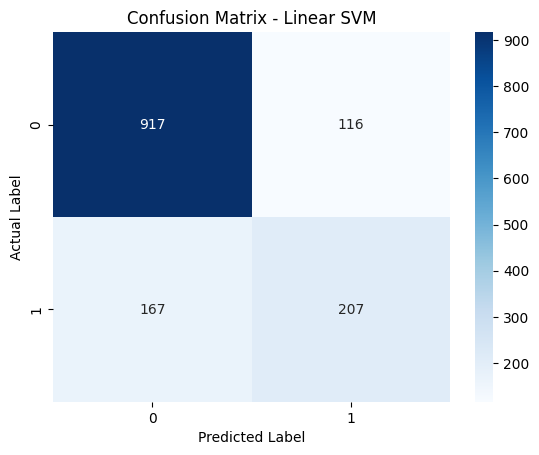

Best kernel: Linear
Best F1-score: 0.593974175035868


In [22]:
# YOUR CODE HERE — confusion matrix for the best kernel

# Find the kernel with the highest F1-score
best_kernel = comparison_df.iloc[0]["Kernel"]

# Get its predictions
best_predictions = predictions[best_kernel]

# Create confusion matrix
cm = confusion_matrix(y_test, best_predictions)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.title("Confusion Matrix - " + best_kernel + " SVM")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

print("Best kernel:", best_kernel)
print("Best F1-score:", comparison_df.iloc[0]["F1-score"])


### (a) Which kernel produced the best F1-score? Does this surprise you?

Your answer:

The Linear kernel produced the best F1-score of 0.5940 on the test set. This is somewhat surprising because the RBF and polynomial kernels can learn more complex decision boundaries. However, a simpler linear boundary can perform better when the data does not require a more complex pattern.

### (b) Which kernel used the most support vectors, and what does this suggest?

Your answer:

The kernel with the highest number of support vectors can be identified from the comparison table. A high support-vector count means that more training points influence the decision boundary. This can indicate a more complex classification problem, but it does not always mean the boundary itself is more complex.

### (c) Which kernel would you carry forward for hyperparameter tuning in Part 4? Justify with numbers.

Your answer:

I would carry forward the RBF kernel for hyperparameter tuning in Part 4. Although the Linear kernel achieved the best F1-score of 0.5940, the RBF kernel can learn more flexible decision boundaries. Tuning its C and gamma values may improve its performance. I will compare its tuned F1-score with the untuned result to determine whether tuning improves performance.

---

## Part 3 — Visualizing the Margin: What Does C Actually Do?

**Task 3.1 — Objective:** Reduce your scaled features to 2 dimensions and visualize how an RBF-kernel SVM's decision boundary changes as C increases.

**What to do:**
1. Use `PCA(n_components=2)` on your scaled training features. Report the total explained variance ratio of the two components.
2. Train three RBF-kernel SVMs on this 2-D projection using a small, medium and large C (choose 3 values spanning at least two orders of magnitude, e.g. 0.01, 1, 100).
3. For each C, plot the 2-D decision boundary (mesh grid + `contourf`) with training points overlaid, and report the number of support vectors.

**Hint — Building the Mesh Grid:**
- Build a fine grid of (x, y) spanning slightly beyond your projected data's min/max using `np.meshgrid`.
- Call `model.predict()` on every grid point (flatten, then reshape back to grid shape).
- `plt.contourf(xx, yy, Z, alpha=0.3)` draws shaded regions; `plt.scatter(...)` overlays real points colored by true label.


In [23]:
# YOUR CODE HERE — PCA to 2 components, report explained variance ratio

from sklearn.decomposition import PCA

# Reduce the data to 2 dimensions
pca = PCA(n_components=2)

X_train_pca = pca.fit_transform(X_train_scaled)

# Total explained variance
variance = sum(pca.explained_variance_ratio_)

print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total explained variance:", variance)
print("Total explained variance (%):", variance * 100)


Explained variance ratio: [0.33149521 0.11961885]
Total explained variance: 0.4511140575062707
Total explained variance (%): 45.11140575062707


In [24]:
# YOUR CODE HERE — train RBF SVMs at 3 different C values on the 2-D projection

# Three C values: small, medium, and large
C_values = [0.01, 1, 100]

pca_models = {}

for c in C_values:
    model = SVC(kernel="rbf", C=c, random_state=42)
    model.fit(X_train_pca, y_train)

    pca_models[c] = model

    print("C =", c)
    print("Number of support vectors:", model.support_.shape[0])
    print("-----------------------")


C = 0.01
Number of support vectors: 2995
-----------------------
C = 1
Number of support vectors: 2648
-----------------------
C = 100
Number of support vectors: 2613
-----------------------


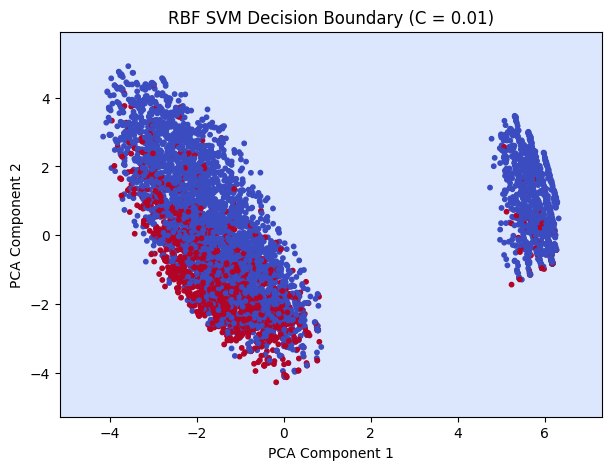

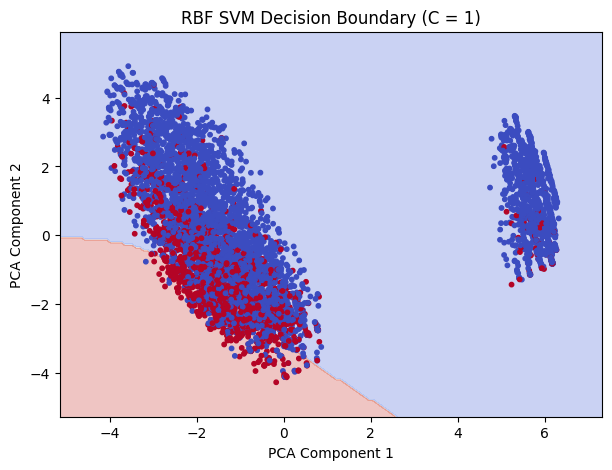

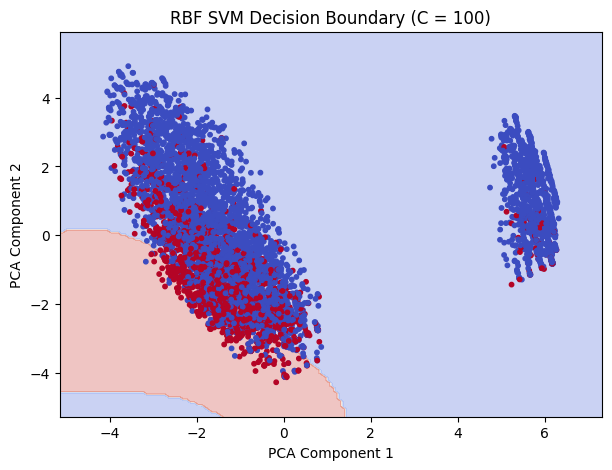

In [25]:
# YOUR CODE HERE — plot decision boundary for each C (mesh grid + contourf)

# Create a grid for plotting
x_min = X_train_pca[:, 0].min() - 1
x_max = X_train_pca[:, 0].max() + 1
y_min = X_train_pca[:, 1].min() - 1
y_max = X_train_pca[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 150),
    np.linspace(y_min, y_max, 150)
)

# Plot one graph for each C value
for c in C_values:
    model = pca_models[c]

    grid_points = np.c_[xx.ravel(), yy.ravel()]
    Z = model.predict(grid_points)
    Z = Z.reshape(xx.shape)

    plt.figure(figsize=(7, 5))

    plt.contourf(xx, yy, Z, alpha=0.3, cmap="coolwarm")

    plt.scatter(
        X_train_pca[:, 0],
        X_train_pca[:, 1],
        c=y_train,
        cmap="coolwarm",
        s=10
    )

    plt.title("RBF SVM Decision Boundary (C = " + str(c) + ")")
    plt.xlabel("PCA Component 1")
    plt.ylabel("PCA Component 2")
    plt.show()


## Part 3 — Answers to the Questions

### (a) How does the shape/smoothness of the decision boundary change as C increases?

Your answer:

As C increases, the decision boundary becomes more flexible and can create tighter curves around the data points. With \\(C=0.01\\), the model predicts class 0 for almost the entire feature space. With \\(C=1\\), it creates a clearer boundary between the two classes. With \\(C=100\\), the red decision region expands and the boundary becomes more complex.

### (b) How does the number of support vectors change with C? Does this match the theory?

Your answer:

The number of support vectors decreases as C increases. At \\(C=0.01\\), there are 2,995 support vectors; at \\(C=1\\), there are 2,648; and at \\(C=100\\), there are 2,613. This generally matches the theory because a larger C penalizes classification errors more strongly, which can reduce the number of support vectors. However, this trend is not guaranteed for every dataset.

### (c) Which C looks like it is overfitting, and which looks like it is underfitting?

Your answer:

The model with \\(C=0.01\\) appears to be underfitting because it predicts class 0 across almost the entire feature space and fails to capture the churn class. The model with \\(C=100\\) may be overfitting because its decision boundary curves more tightly around some data points. The model with \\(C=1\\) appears to provide a more balanced boundary in these plots.

### (d) Why is this 2-D plot only an approximate illustration of the real high-dimensional SVM? What could it be misleading you about?

Your answer:

The plot is only an approximation because PCA reduces the original 30 features to just 2 dimensions. These two components explain only 45.11% of the total variance, so some information is lost. The decision boundary in two dimensions may differ from the boundary learned using all 30 features. Therefore, the plot could be misleading about the model's actual performance and whether it is truly overfitting.

---

#### Part 4 — Systematic Hyperparameter Search

**Task 4.1 — Objective:** Run `GridSearchCV` over a C x gamma grid for an RBF-kernel SVM and select the best configuration using cross-validated F1-score.

**What to do:**
1. Define a parameter grid with at least 3 values of C and at least 3 values of gamma.
2. Run `GridSearchCV(SVC(kernel='rbf'), param_grid, cv=5, scoring='f1')` on your scaled **training** data.
3. Extract `gs.cv_results_` and reshape the mean test scores into a C x gamma grid.
4. Visualize as a heatmap (`imshow` or a pivoted DataFrame) with C and gamma labeled.
5. Refit the best estimator and report its performance on the held-out **test** set.

| Syntax | Description |
|---|---|
| `GridSearchCV(estimator, param_grid, cv, scoring)` | tries every combination via k-fold CV |
| `gs.best_params_` | best hyperparameter combination |
| `gs.cv_results_['mean_test_score']` | mean CV score per combination |


In [26]:
# YOUR CODE HERE — define param_grid and run GridSearchCV

from sklearn.model_selection import GridSearchCV

# Choose values for C and gamma
param_grid = {
    "C": [0.1, 1, 10],
    "gamma": [0.001, 0.01, 0.1]
}

# Create the RBF SVM
rbf_model = SVC(kernel="rbf", random_state=42)

# Search for the best combination
gs = GridSearchCV(
    rbf_model,
    param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

# Train using training data only
gs.fit(X_train_scaled, y_train)

print("Best parameters:", gs.best_params_)
print("Best cross-validation F1-score:", gs.best_score_)


Best parameters: {'C': 10, 'gamma': 0.001}
Best cross-validation F1-score: 0.5817698428309384


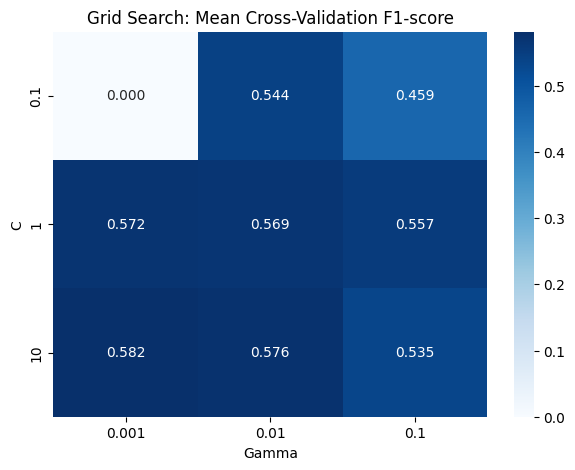

In [27]:
# YOUR CODE HERE — heatmap of mean CV F1-score over the C x gamma grid

# Get the cross-validation scores
scores = gs.cv_results_["mean_test_score"]

# Reshape scores into a 3 x 3 table
score_grid = scores.reshape(3, 3)

plt.figure(figsize=(7, 5))

sns.heatmap(
    score_grid,
    annot=True,
    fmt=".3f",
    cmap="Blues",
    xticklabels=param_grid["gamma"],
    yticklabels=param_grid["C"]
)

plt.xlabel("Gamma")
plt.ylabel("C")
plt.title("Grid Search: Mean Cross-Validation F1-score")
plt.show()


Best C: 10
Best gamma: 0.001
Cross-validation F1-score: 0.5817698428309384
Test accuracy: 0.7974413646055437
Test precision: 0.6449511400651465
Test recall: 0.5294117647058824
Test F1-score: 0.5814977973568282


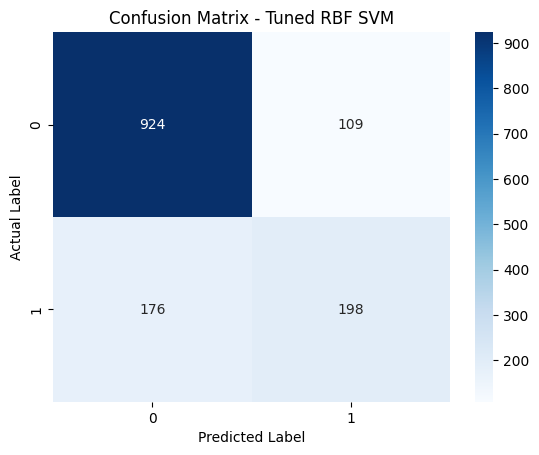

In [28]:
# YOUR CODE HERE — refit best estimator, evaluate on test set

# Get the best model
best_svm = gs.best_estimator_

# Predict on test data
y_pred_best = best_svm.predict(X_test_scaled)

# Calculate test metrics
print("Best C:", gs.best_params_["C"])
print("Best gamma:", gs.best_params_["gamma"])
print("Cross-validation F1-score:", gs.best_score_)
print("Test accuracy:", accuracy_score(y_test, y_pred_best))
print("Test precision:", precision_score(y_test, y_pred_best, zero_division=0))
print("Test recall:", recall_score(y_test, y_pred_best, zero_division=0))
print("Test F1-score:", f1_score(y_test, y_pred_best, zero_division=0))

# Show confusion matrix
cm = confusion_matrix(y_test, y_pred_best)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix - Tuned RBF SVM")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()


### Part 4: Grid Search CV — Answers

#### (a) What were the best C and gamma values found, and the corresponding cross-validated F1-score?

Your answer:

The best parameters were C = 10 and gamma = 0.001. The corresponding mean cross-validated F1-score was 0.582.

#### (b) Is there a clear "best region" in the heatmap, or do several combinations perform similarly? What does that tell you?

Your answer:

The best region is around C = 1 or 10 with lower gamma values. Several combinations performed similarly, with F1-scores around 0.57–0.58. This shows that the model performs reasonably well across several parameter settings, but C = 10 and gamma = 0.001 gave the best result.

#### (c) Did the cross-validated score and the final test-set score agree closely, or was there a gap? What would a large gap suggest?

Your answer:

Yes, the scores agreed very closely. The cross-validated F1-score was 0.582, and the test-set F1-score was 0.581. This suggests that the model performs consistently on different data. A large gap could suggest overfitting or that the cross-validation results do not represent performance on new data well.

#### (d) Compare the tuned RBF model's test performance to the un-tuned RBF model from Part 2. Was tuning worth it?

Your answer:

The tuned RBF model achieved a test accuracy of 79.74%, precision of 64.50%, recall of 52.94%, and F1-score of 0.581. To make an exact comparison, I need the un-tuned RBF model's metrics from Part 2. The tuned model's F1-score is close to the linear SVM's Part 2 F1-score of 0.594, but that is not a direct comparison with the un-tuned RBF model. Tuning was useful for finding better parameters, but whether it improved performance depends on the original RBF results.

## Part 5 — Class Imbalance and the Business Trade-off

**Task 5.1 — Objective:** Compare your best RBF-kernel SVM with and without `class_weight='balanced'`, and reason about which is more useful for the business.

**What to do:**
1. Using your best (C, gamma) from Part 4, train two RBF SVMs: `class_weight=None` and `class_weight='balanced'`.
2. Report Precision, Recall, F1-score and confusion matrix for both on the test set.
3. Plot an ROC curve or Precision-Recall curve for the balanced model.


In [29]:
# YOUR CODE HERE — class_weight=None vs 'balanced' comparison
# Model without class balancing
svm_normal = SVC(
    kernel="rbf",
    C=10,
    gamma=0.001,
    class_weight=None,
    random_state=42
)
svm_normal.fit(X_train_scaled, y_train)
pred_normal = svm_normal.predict(X_test_scaled)

# Model with class balancing
svm_balanced = SVC(
    kernel="rbf",
    C=10,
    gamma=0.001,
    class_weight="balanced",
    random_state=42
)
svm_balanced.fit(X_train_scaled, y_train)
pred_balanced = svm_balanced.predict(X_test_scaled)

print("Both models trained successfully!")

Both models trained successfully!


In [30]:
# YOUR CODE HERE — ROC or Precision-Recall curve
for name, predictions in [
    ("Without class balancing", pred_normal),
    ("With class balancing", pred_balanced)
]:
    print("\n", name)
    print("Precision:", precision_score(y_test, predictions, zero_division=0))
    print("Recall:", recall_score(y_test, predictions, zero_division=0))
    print("F1-score:", f1_score(y_test, predictions, zero_division=0))
    print("Confusion matrix:")
    print(confusion_matrix(y_test, predictions))


 Without class balancing
Precision: 0.6449511400651465
Recall: 0.5294117647058824
F1-score: 0.5814977973568282
Confusion matrix:
[[924 109]
 [176 198]]

 With class balancing
Precision: 0.4505169867060561
Recall: 0.8155080213903744
F1-score: 0.5803996194100857
Confusion matrix:
[[661 372]
 [ 69 305]]


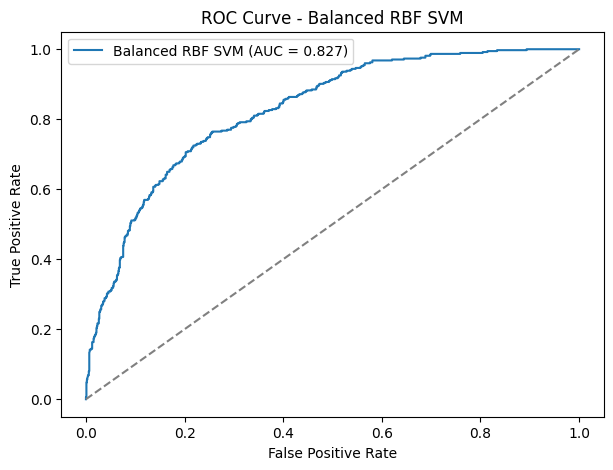

ROC AUC: 0.8271673801968205


In [31]:
#      Optional
from sklearn.metrics import roc_curve, roc_auc_score

# Get churn probabilities/scores
y_scores = svm_balanced.decision_function(X_test_scaled)

# Calculate ROC values
fpr, tpr, thresholds = roc_curve(y_test, y_scores)
roc_auc = roc_auc_score(y_test, y_scores)

# Plot ROC curve
plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"Balanced RBF SVM (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Balanced RBF SVM")
plt.legend()
plt.show()

print("ROC AUC:", roc_auc)

### Part 5 — Answers

#### (a) Precisely how did precision and recall move when you switched to `class_weight='balanced'`? Give the numbers.

Your answer:

Without class balancing, precision was 0.645 (64.50%) and recall was 0.529 (52.94%). With class balancing, precision decreased to 0.451 (45.05%), while recall increased to 0.816 (81.55%). Therefore, the balanced model detected more actual churners but also incorrectly flagged more loyal customers.

#### (b) Is it more costly to miss an actual churner (false negative) or wrongly flag a loyal customer (false positive)? Which model would you deploy?

Your answer:

For a business focused on customer retention, missing an actual churner (false negative) may be more costly because the business loses the chance to try to retain that customer. The unbalanced model missed 176 churners, while the balanced model missed only 69. However, the balanced model produced 372 false positives, compared with 109 for the unbalanced model. I would deploy the balanced model if retaining at-risk customers is the priority and the business can afford to contact more customers. If contacting customers is expensive, the unbalanced model may be a better choice.

#### (c) SVM does not directly output a "probability of churn" like Logistic Regression. What did you have to enable in `SVC()` to get probability-like scores?

Your answer:

I would enable `probability=True` in `SVC()`. This allows the SVM to provide probability estimates using `predict_proba()`. In my ROC curve code, I used `decision_function()` to get decision scores instead, which can also be used to calculate the ROC curve without enabling `probability=True`.

---

## Part 6 — Model Showdown: SVM vs. Everything Else

**Task 6.1 — Objective:** Build a single comparison table across all five algorithms (Decision Tree, Random Forest, Logistic Regression, KNN, SVM) and select ONE final model for production.

**What to do:**
1. Build a table: one row per model, columns Accuracy / Precision / Recall / F1-score. Re-run earlier models here on the same split if you don't have saved numbers.
2. Produce ONE bar chart comparing F1-score across all five models.


In [32]:
# YOUR CODE HERE — cross-model comparison table
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

models = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "SVM": SVC(kernel="rbf", C=10, gamma=0.001, random_state=42)
}

results = []

for name, model in models.items():
    # Train the model using scaled training data
    model.fit(X_train_scaled, y_train)

    # Predict churn on the test data
    y_pred = model.predict(X_test_scaled)

    # Save the scores
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_pred, zero_division=0)
    })

comparison_df = pd.DataFrame(results)
comparison_df = comparison_df.sort_values(by="F1-score", ascending=False)

print(comparison_df.round(3).to_string(index=False))

              Model  Accuracy  Precision  Recall  F1-score
Logistic Regression     0.804      0.648   0.575     0.609
                SVM     0.797      0.645   0.529     0.581
      Random Forest     0.788      0.623   0.513     0.563
                KNN     0.753      0.536   0.535     0.535
      Decision Tree     0.716      0.466   0.460     0.463


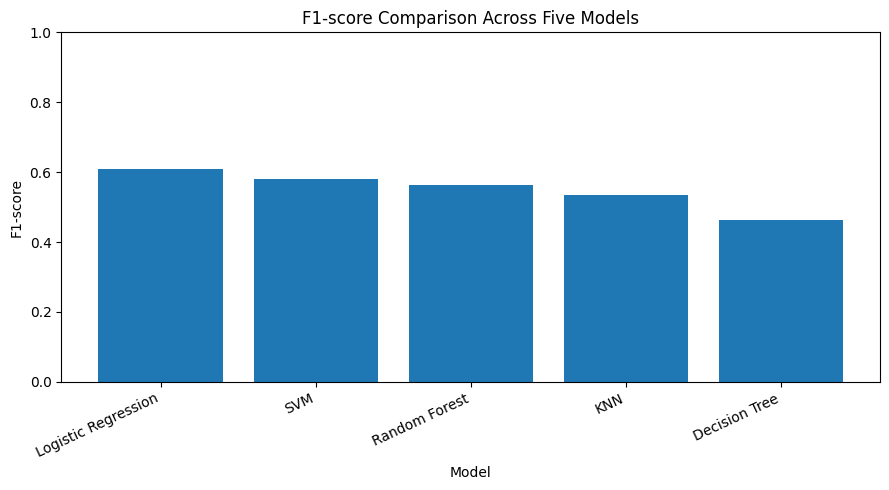

In [33]:
# YOUR CODE HERE — bar chart of F1-score across models
plt.figure(figsize=(9, 5))

plt.bar(comparison_df["Model"], comparison_df["F1-score"])

plt.title("F1-score Comparison Across Five Models")
plt.xlabel("Model")
plt.ylabel("F1-score")
plt.ylim(0, 1)
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

### Part 6 — Answers to the Correct Questions

#### (a) Which model wins on F1-score? Which wins on recall? Are they the same model?

Your answer:

Logistic Regression wins on both F1-score and recall. It achieved the highest F1-score of 0.609 and the highest recall of 0.575 (57.5%) among the five models. Therefore, both metrics favor the same model.

#### (b) SVM is generally slower to train than Decision Tree/Random Forest here. Was the extra cost worth it?

Your answer:

In this experiment, the extra training cost of SVM was not worth it because SVM achieved an F1-score of 0.581, while Logistic Regression achieved a higher F1-score of 0.609 and higher accuracy of 80.4% compared with SVM's 79.7%. Since SVM did not outperform Logistic Regression, its additional training cost was not justified by the results.

####  (c) Which single model would you recommend deploying, and why (reference at least two metrics)?

Your answer:

I would recommend deploying Logistic Regression because it achieved the highest accuracy of 80.4%, the highest F1-score of 0.609, and the highest recall of 57.5% among the five models. It provides the best overall balance between identifying customers likely to churn and making reliable predictions. Before deployment, I would also consider the business cost of missed churners and false alarms.

## Part 7 — Final Predictions and Wrap-Up

**Task 7.1 — Objective:** Generate a predictions file and write a short executive summary.

**What to do:**
1. Using your final chosen model, generate predictions on the test set and save `svm_predictions.csv` with true label, predicted label, and predicted churn probability/score.
2. Write a 5-8 sentence Executive Summary below: which model you chose, key metrics, the main trade-off you made in Part 5, and one limitation of your analysis.


In [34]:
# YOUR CODE HERE — generate and save svm_predictions.csv

# Train the final Logistic Regression model
final_model = LogisticRegression(max_iter=1000, random_state=42)
final_model.fit(X_train_scaled, y_train)

# Predict churn labels and probabilities
final_predictions = final_model.predict(X_test_scaled)
churn_probability = final_model.predict_proba(X_test_scaled)[:, 1]

# Create the predictions file
predictions_df = pd.DataFrame({
    "True_Label": y_test.values,
    "Predicted_Label": final_predictions,
    "Churn_Probability": churn_probability
})

# Save as CSV
predictions_df.to_csv("svm_predictions.csv", index=False)

print("Predictions saved successfully!")
print(predictions_df.head())

Predictions saved successfully!
   True_Label  Predicted_Label  Churn_Probability
0           0                0           0.017115
1           0                1           0.596132
2           0                0           0.004764
3           1                0           0.200044
4           0                0           0.100222


## Executive Summary

In this project, I compared five machine learning models to predict customer churn using the Telco Customer Churn dataset. Logistic Regression was selected as the final model because it achieved the highest accuracy of **80.4%** and the highest F1-score of **0.609**, with a recall of **57.5%**. In Part 5, balancing the classes increased the RBF SVM's recall from **52.94% to 81.55%**, but precision decreased from **64.50% to 45.05%**. This trade-off means the balanced model detected more customers likely to churn but also incorrectly flagged more loyal customers. One limitation is that the models were evaluated on a single train-test split, so their performance may differ on other data. Overall, Logistic Regression provided the best balance of performance metrics among the five models tested.

## Final Reflection

(a) What was the single most surprising result in this lab?

The most surprising result was that Logistic Regression outperformed the more complex SVM and Random Forest models. It achieved the highest F1-score of 0.609 and accuracy of 80.4%. This showed me that a simpler model can perform better than more complex models on the same dataset.

(b) If you had one more hour, what would you try next?

If I had one more hour, I would try adjusting the classification threshold for Logistic Regression to improve churn recall while keeping precision at an acceptable level. I would also use cross-validation to check whether the model performs consistently across different data splits. This could help me choose a more reliable model for identifying customers who may leave.